<a href="https://colab.research.google.com/github/chini111/chest-xray-classification/blob/main/chest_xray_yolo_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
!ls /content/drive/MyDrive/


'archive (1)'	    HAM10000_metadata.csv   yolo_results
'Colab Notebooks'  'pneumonia data set'


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 5.9 MB/s eta 0:00:00


In [ ]:
!cp -r '/content/drive/MyDrive/archive (1)' /content/chest_xray
!ls /content/chest_xray/

Data  train.zip


In [ ]:
!unzip '/content/chest_xray/train.zip' -d /content/chest_xray/
!ls /content/chest_xray/

Archive:  /content/chest_xray/train.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/chest_xray/train.zip or
        /content/chest_xray/train.zip.zip, and cannot find /content/chest_xray/train.zip.ZIP, period.
Data  train.zip


In [ ]:
!ls /content/chest_xray/Data/

test  train


In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11n-cls.pt')

model.train(
    data='/content/chest_xray/Data/train',
    epochs=20,
    imgsz=224,
    batch=16,
    project='/content/yolo_results',
    name='chest_xray_classification'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/chest_xray/Data/train, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, fo

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c18f7ba82d0>
curves: []
curves_results: []
fitness: 0.9874497950077057
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9748995900154114, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9874497950077057}
save_dir: PosixPath('/content/yolo_results/chest_xray_classification')
speed: {'preprocess': 0.12961830923697096, 'inference': 3.369360603413948, 'loss': 0.0003909297184548789, 'postprocess': 0.0004830190763309054}
top1: 0.9748995900154114
top5: 1.0

In [ ]:
# Evaluate on test set
model_best = YOLO('/content/yolo_results/chest_xray_classification/weights/best.pt')

results = model_best.val(
    data='/content/chest_xray/Data/test',
    split='test'
)

print(f"Top-1 Accuracy: {results.top1:.4f}")
print(f"Top-5 Accuracy: {results.top5:.4f}")

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
WARNING ⚠️ Dataset 'split=train' not found at /content/chest_xray/Data/test/train
Found 1238 images in subdirectories. Attempting to split...
Splitting /content/chest_xray/Data/test (3 classes, 1238 images) into 80% train, 20% val...
Split complete in /content/chest_xray/Data/test_split ✅
WARNING ⚠️ Dataset 'split=test' not found, using 'split=val' instead.
train: /content/chest_xray/Data/test_split/train... found 989 images in 3 classes ✅ 
val: /content/chest_xray/Data/test_split/val... found 249 images in 3 classes ✅ 
test: /content/chest_xray/Data/test_split/val... found 249 images in 3 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2823.5±1329.9 MB/s, size: 525.2 KB)
test: Scanning /content/chest_xray/Data/test_split/val... 249 images, 0 corrupt: 100% ━━━━━━━━━━━━ 249/249 4.6Kit/s 0.1s
test: New cach

In [ ]:
L

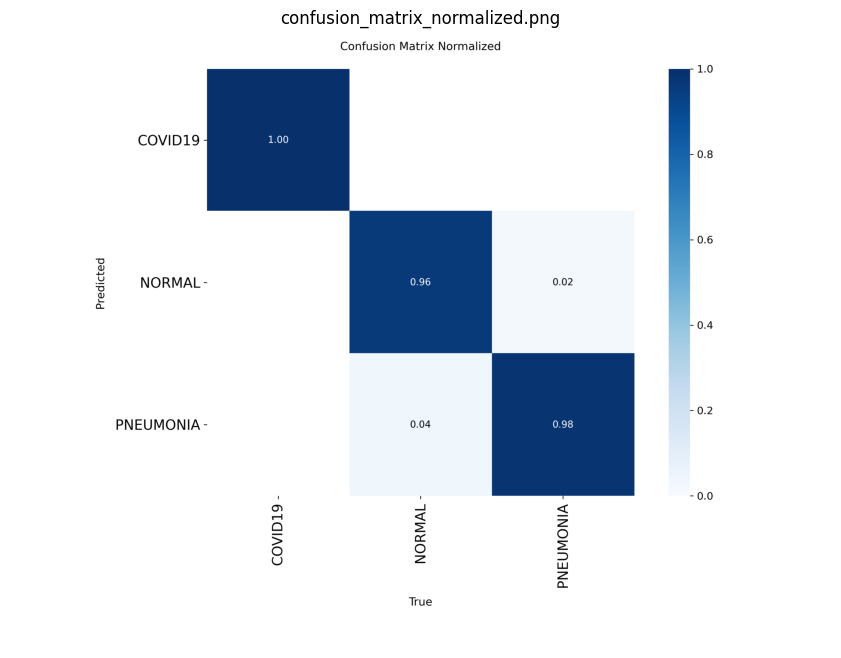

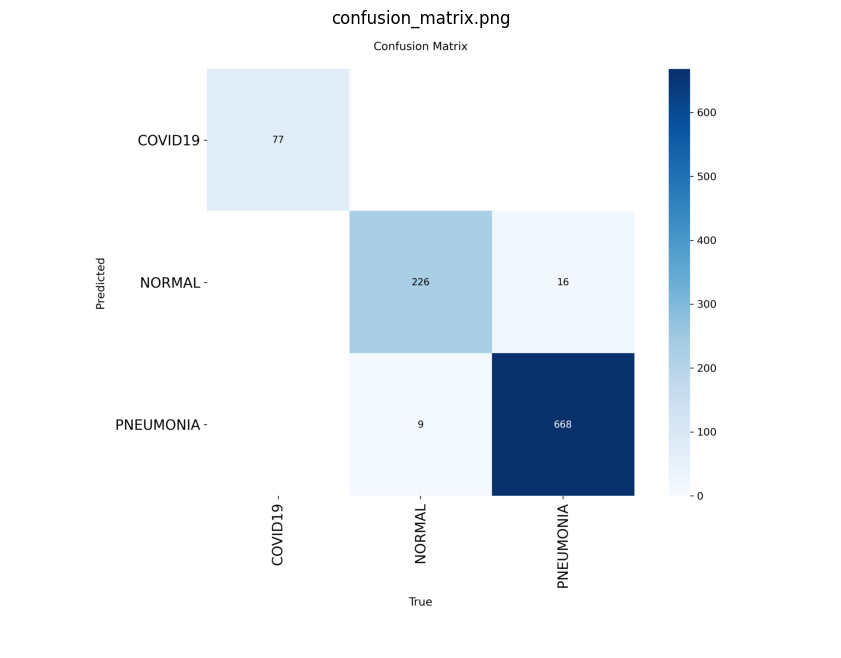

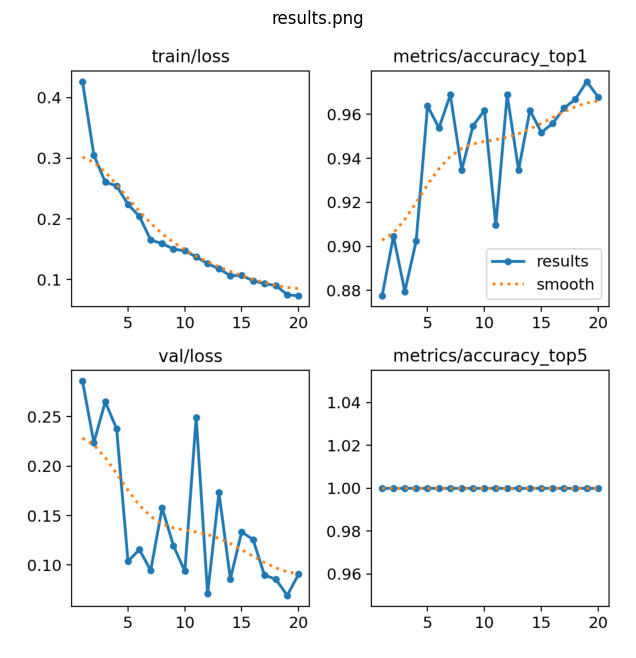

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob

result_images = glob.glob('/content/yolo_results/chest_xray_classification/*.png')
for img_path in result_images:
    img = mpimg.imread(img_path)
    plt.figure(figsize=(12,8))
    plt.imshow(img)
    plt.axis('off')
    plt.title(img_path.split('/')[-1])
    plt.show()